# 06 dataset comparison

Aggregate exploration only. Run download and preprocessing first. Labels and annotation methods differ across datasets. Test examples are not used for model tuning or qualitative error analysis. Source terms and decisions: `../docs/DATASETS.md`.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
root = Path.cwd().resolve()
while not (root / 'src' / 'preprocess.py').exists():
    if root == root.parent:
        raise RuntimeError('Open this notebook inside the repository')
    root = root.parent
sys.path.insert(0, str(root))
from src.explore_data import explore, comparison


,dataset,platform,annotation,task,positive_label,negative_label,original_source_size,original_loaded_size,processed_size,train,dev,test,positive_percent,context_count,subtypes,limitations
0,semeval2018,Twitter,Manual fine-grained irony annotation,irony_detection,ironic,non_ironic,4618,4618,4618,3067,767,784,48.116068,0,"[""0"", ""1"", ""2"", ""3""]",Hashtag collection bias; subtype categories ar...
1,semeval2022,Twitter,"Author-provided intended sarcasm, expert figur...",sarcasm_detection,sarcastic,non_sarcastic,4868,4868,4850,2761,689,1400,21.896907,0,"[""[\""irony\"", \""overstatement\""]"", ""[\""irony\""...",Rephrasings and categories available in traini...
2,figlang2020/twitter,Twitter,Shared-task sarcasm labels; see task report fo...,sarcasm_detection,sarcastic,non_sarcastic,6800,6800,6546,3797,949,1800,51.894287,6546,[],No thread/author IDs. Shared context messages ...
3,figlang2020/reddit,Reddit,Shared-task sarcasm labels; see task report fo...,sarcasm_detection,sarcastic,non_sarcastic,6200,6200,6197,3515,882,1800,50.008068,6197,[],No thread/author IDs. Shared context messages ...
4,sarc,Reddit,Author self-annotation using /s,sarcasm_detection,sarcastic,non_sarcastic,321748,12000,11749,7802,1947,2000,49.799983,11749,[],"Sampled official test, not full published benc..."
5,nikesh66,Unverified,Undocumented; yes/no labels interpreted using ...,sarcasm_detection,sarcastic,non_sarcastic,5000,5000,224,162,31,31,50.000000,0,[],Exploratory only. No license or collection/ann...
6,hahackathon,Twitter / short jokes,"20 human annotators per text, ages 18-70; aggr...",humor_detection,humorous,non_humorous,10000,10000,9996,7996,1000,1000,61.794718,0,[],Humor is subjective and may overlap sarcasm. M...
7,semeval2022_idioms,Web text,Human annotation of potentially idiomatic mult...,idiomaticity_detection,idiomatic_usage,non_idiomatic_usage,3793,3793,3793,3043,378,372,51.252307,3793,[],"Web-domain auxiliary task, not social-media sa..."


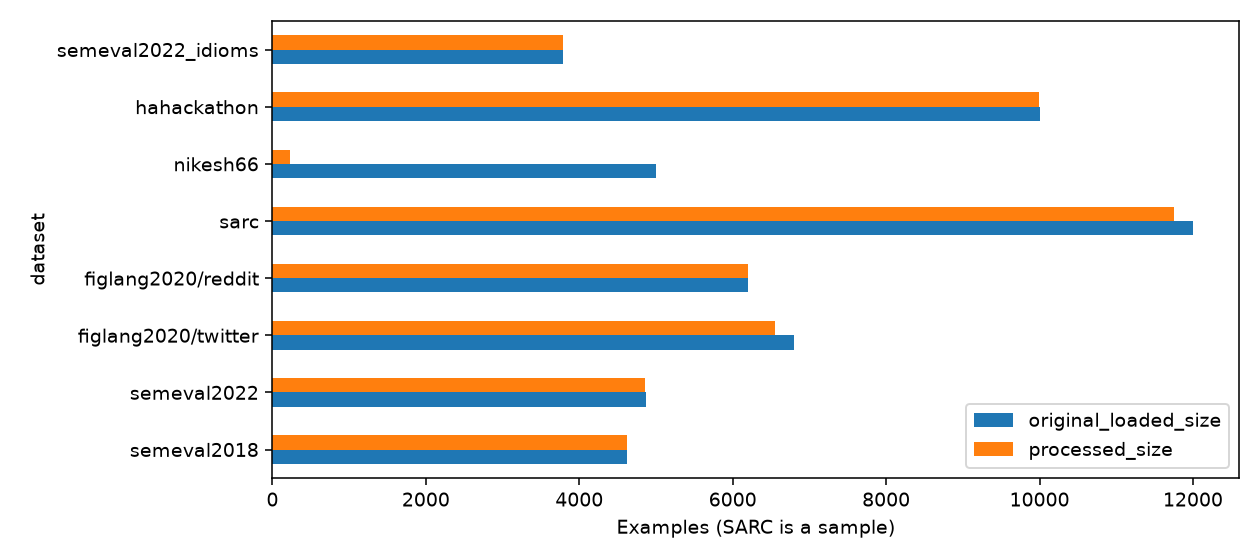

In [2]:
table = comparison()
display(table)
display(Image(filename=str(root / 'results/figures/dataset_comparison.png')))


## Report guidance

SemEval 2018 is the primary irony benchmark. iSarcasmEval uses intended sarcasm, FigLang provides conversations, SARC uses self-annotation, and nikesh66 has unverified provenance. Do not compare positive rates as if annotation definitions were identical. Describe SARC as an official-release sample, and nikesh66 as exploratory. Use development data for model choices and reserve test data for final scoring.